In [1]:
import requests

url = "https://data.mendeley.com/public-files/datasets/f35jp46gms/files/89e096b4-ec79-4e34-a81c-778b6d701f4b/file_downloaded"

response = requests.get(url, stream=True, timeout=120)
response.raise_for_status()

output_path = "/kaggle/working/carambola_dataset.zip"

with open(output_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Download completed!")

Download completed!


In [2]:
import zipfile

zip_path = "/kaggle/working/carambola_dataset.zip"
extract_path = "/kaggle/working/carambola_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [3]:
import os

extract_path = "/kaggle/working/carambola_dataset"

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:3]:
        print(f"{indent}    {file}")

    if level >= 3:
        dirs[:] = []

carambola_dataset/
    Original Dataset/
        Citrus Nutrient Deficiency (Yellow Leaves)/
            450.jpg
            284.jpg
            272.jpg
        Healthy Leaves/
            450.jpg
            284.jpg
            272.jpg
        Insect Hole leaves/
            450.jpg
            284.jpg
            272.jpg
        Unhealthy Fruits/
            450.jpg
            284.jpg
            272.jpg
        Healthy Fruits/
            450.jpg
            284.jpg
            272.jpg


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [5]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root="/kaggle/working/carambola_dataset/Original Dataset",
    transform=transform
)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_ds, test_ds = torch.utils.data.random_split(
    dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=64, shuffle=False)

print("Train:", len(train_ds))
print("Test:", len(test_ds))
print("Total:", len(dataset))
print("Classes:", dataset.classes)

Train: 2094
Test: 524
Total: 2618
Classes: ['Citrus Nutrient Deficiency (Yellow Leaves)', 'Healthy Fruits', 'Healthy Leaves', 'Insect Hole leaves', 'Unhealthy Fruits']


In [6]:
# CNN Build
class CarambolaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolutional Block
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        # ANN / Classification Layer
        input_neurons = 16 * 32 * 32
        self.cls = nn.Linear(input_neurons, 5)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)
        x = self.cls(x)

        return x

model = CarambolaCNN().to(device)
print(model)

CarambolaCNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (cls): Linear(in_features=16384, out_features=5, bias=True)
)


In [7]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for ep in range(10):
    model.train()
    correct, total = 0, 0

    for img, label in train_dl:
        img, label = img.to(device), label.to(device)

        optimizer.zero_grad()
        output = model(img)
        loss = loss_fn(output, label)

        loss.backward()
        optimizer.step()

        correct += torch.sum(torch.argmax(output, dim=1) == label).item()
        total += label.size(0)

    print(f"Ep {ep+1}: Train Acc {correct/total}")

Ep 1: Train Acc 0.4145176695319962
Ep 2: Train Acc 0.7617000955109837
Ep 3: Train Acc 0.8051575931232091
Ep 4: Train Acc 0.8371537726838586
Ep 5: Train Acc 0.8481375358166189
Ep 6: Train Acc 0.8624641833810889
Ep 7: Train Acc 0.8610315186246418
Ep 8: Train Acc 0.8615090735434575
Ep 9: Train Acc 0.8829990448901623
Ep 10: Train Acc 0.9030563514804203


In [8]:
model.eval()

correct, total = 0, 0
test_loss = 0.0

with torch.no_grad():
    for img, label in test_dl:
        img, label = img.to(device), label.to(device)

        output = model(img)
        loss = loss_fn(output, label)

        test_loss += loss.item() * label.size(0)

        predicted = torch.argmax(output, dim=1)
        correct += (predicted == label).sum().item()
        total += label.size(0)

test_accuracy = correct / total
test_loss = test_loss / total
 
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 89.89%
Test Loss: 0.3011


In [9]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:", total_params)

Trainable parameters: 83317


In [10]:
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
  x = model.conv1(x)
  early = F.relu(x).cpu()[0] #ealry layer features 8
  x = model.pool(x)
  x = model.conv2(x)
  last = F.relu(x).cpu()[0] #last layer features 16

print(early.shape)
print(last.shape)


torch.Size([8, 128, 128])
torch.Size([16, 64, 64])


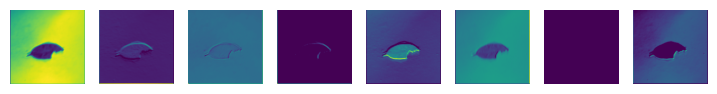

In [11]:
plt.figure(figsize=(9,2))
for i in range(8):
  plt.subplot(1,8,i+1)
  plt.imshow(early[i], cmap='viridis')
  plt.axis('off')



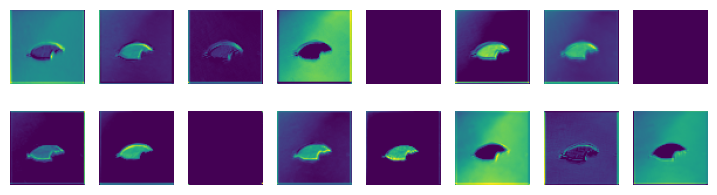

In [12]:
#2nd layer feature
plt.figure(figsize=(9,2.4))
for i in range(16):
  plt.subplot(2,8,i+1)
  plt.imshow(last[i], cmap='viridis')
  plt.axis('off')

In [15]:
torch.save(model.state_dict(), "/kaggle/working/carambola_cnn.pth")